In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import pandas as pd
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.utils import resample
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split, cross_val_score
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import copy
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.compose import TransformedTargetRegressor
import random


In [2]:
#get helper functions
%run '/content/drive/MyDrive/Colab Notebooks/RCC_Beam_Optimization/helper_functions.ipynb'

In [3]:
def train_models( model, X_train, y_train, n_iterations=100):
  n_size = X_train.shape[0]
  models = []
  # Bootstrapping loop
  for i in range(n_iterations):
      X_resampled, y_resampled = resample(X_train, y_train, n_samples=n_size)

      model_copy = copy.deepcopy(model)
      model_copy.fit(X_resampled, y_resampled)
      # Append the trained model to the list of models
      models.append(model_copy)
  return models

In [4]:
def boot_preds(models, test_data):
    predictions = []
    for model in models:
        pred = model.predict(test_data)  # shape: (n_samples, 3)
        pred = correct_invalid_predictions(pred, test_data)
        predictions.append(pred)

    predictions = np.array(predictions)  # shape: (n_models, n_samples, 3)

    mean_pred = np.mean(predictions, axis=0)
    std_pred = np.std(predictions, axis=0)
    lower_bound = np.percentile(predictions, 2.5, axis=0)
    upper_bound = np.percentile(predictions, 97.5, axis=0)

    return mean_pred, lower_bound, upper_bound, std_pred

In [14]:
def parity_with_confidence(models, X_test, y_test, target_names=["b", "d", "Ast"]):
    y_pred, lower_bound, upper_bound, s = boot_preds(models, X_test)

    for i, name in enumerate(target_names):
        r2 = r2_score(y_test[:, i], y_pred[:, i])

        plt.figure(figsize=(6, 5))
        plt.scatter(y_test[:, i], y_pred[:, i], edgecolors='k', alpha=0.7, label="Predicted Values")

        # 95% Prediction Interval
        plt.errorbar(
            y_test[:, i], y_pred[:, i],
            yerr=[y_pred[:, i] - lower_bound[:, i], upper_bound[:, i] - y_pred[:, i]],
            fmt='o', color='gray', alpha=0.5, ecolor='gray', capsize=3,
            label="95% Prediction Interval"
        )

        # Perfect prediction line
        plt.plot(
            [min(y_test[:, i]), max(y_test[:, i])],
            [min(y_test[:, i]), max(y_test[:, i])],
            'r--', lw=2, label="Perfect Prediction"
        )

        plt.text(0.9, 0.1, f'R²: {r2:.3f}', transform=plt.gca().transAxes,
                 ha='right')
        plt.xlabel(f"Actual {name}")
        plt.ylabel(f"Predicted {name}")
        # plt.title(f"Actual vs Predicted for {name}", fontsize=14)
        plt.legend()
        plt.tight_layout()
        plt.savefig(f"parity_plot_{name}.png", dpi=300)
        plt.show()

In [6]:
def plot_r2_rmse(models, X_test, y_test, target_names=["b", "d", "Ast"]):
    """
    Plots the distribution of R² and RMSE across bootstrapped models for each output variable.
    """
    n_targets = y_test.shape[1]
    assert n_targets == len(target_names), "target_names must match the number of output columns"

    # Store results
    r2_scores = np.zeros((len(models), n_targets))
    rmse_scores = np.zeros((len(models), n_targets))

    # Compute metrics for each model and each output
    for i, model in enumerate(models):
        y_pred = model.predict(X_test)
        y_pred = correct_invalid_predictions(y_pred, X_test)
        for j in range(n_targets):
            r2_scores[i, j] = r2_score(y_test[:, j], y_pred[:, j])
            rmse_scores[i, j] = np.sqrt(mean_squared_error(y_test[:, j], y_pred[:, j]))

    # Plot distributions
    fig, axes = plt.subplots(n_targets, 2, figsize=(12, 4 * n_targets))
    if n_targets == 1:  # handle single output case
        axes = np.expand_dims(axes, axis=0)

    for j in range(n_targets):
        # R² distribution
        sns.histplot(r2_scores[:, j], bins=20, kde=True, edgecolor='k', ax=axes[j, 0])
        axes[j, 0].set_title(f"R² Distribution for {target_names[j]}")
        axes[j, 0].set_xlabel("R²")
        axes[j, 0].set_ylabel("Frequency")

        # RMSE distribution
        sns.histplot(rmse_scores[:, j], bins=20, kde=True, color='lightcoral', edgecolor='k', ax=axes[j, 1])
        axes[j, 1].set_title(f"RMSE Distribution for {target_names[j]}")
        axes[j, 1].set_xlabel("RMSE")
        axes[j, 1].set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()


In [7]:
df = pd.read_csv("ensemble_best_designs_1029.csv")

# Features and multi-targets
X = df[['fck', 'fy', 'Mu']].values
y = df[['b', 'd', 'Ast']].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [8]:
df_new = pd.read_csv("new_ensemble_best_designs.csv")
X_test_new = df_new[['fck', 'fy', 'Mu']].values
y_test_new = df_new[['b', 'd', 'Ast']].values

#Gradient boosting regression

In [ ]:
gb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', MultiOutputRegressor(
        TransformedTargetRegressor(
            regressor=GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
            transformer=StandardScaler()
        )
    ))
])

models = train_models(gb_pipeline, X_train, y_train, n_iterations=100)

In [ ]:
joblib.dump(models, 'bootstrapped_gbr_models.pkl')

['bootstrapped_gbr_models.pkl']

In [ ]:
models = joblib.load('bootstrapped_gbr_models.pkl')

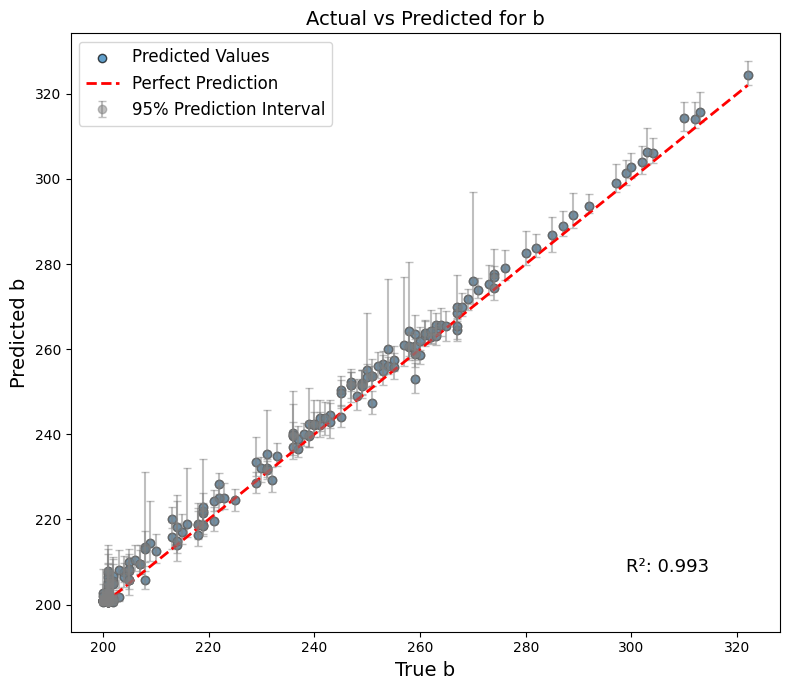

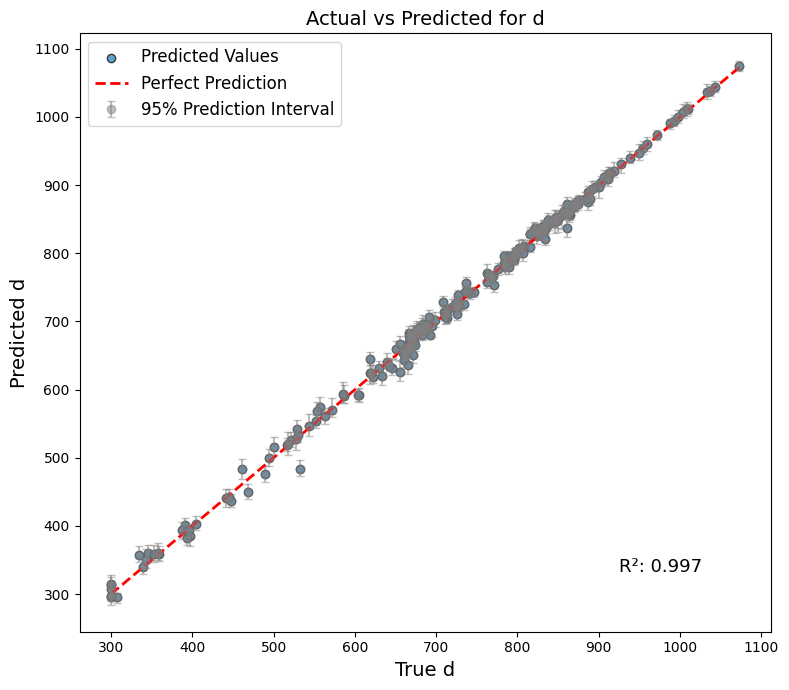

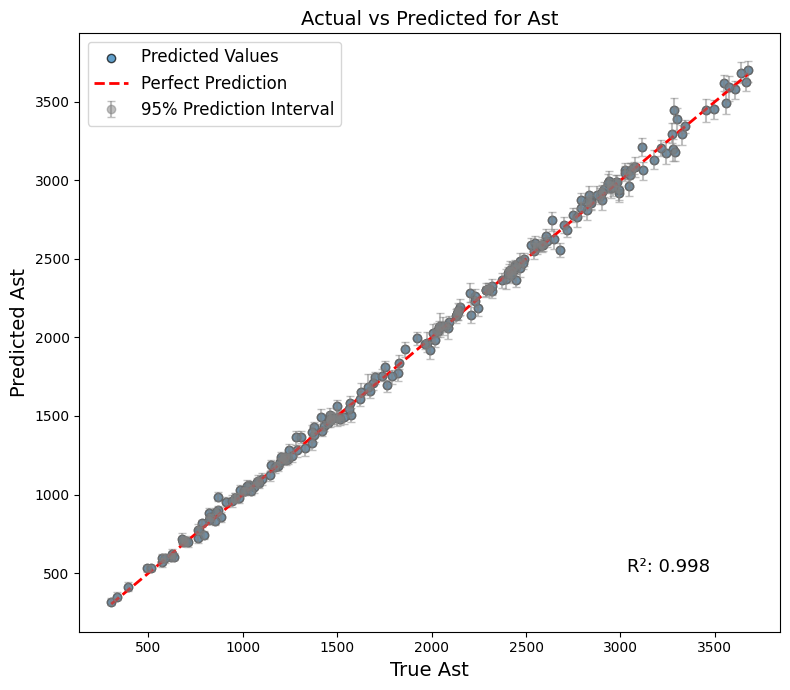

In [ ]:
parity_with_confidence(models, X_test, y_test)

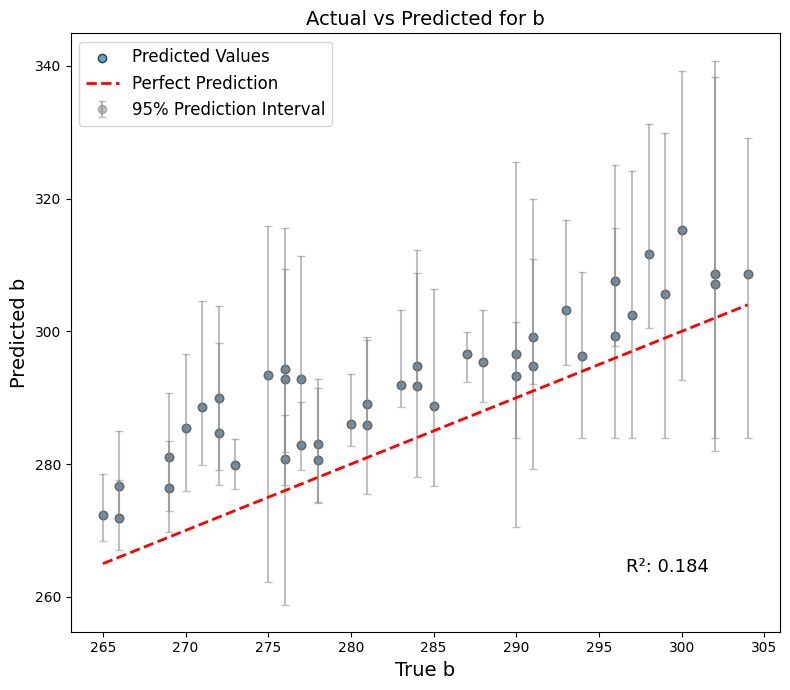

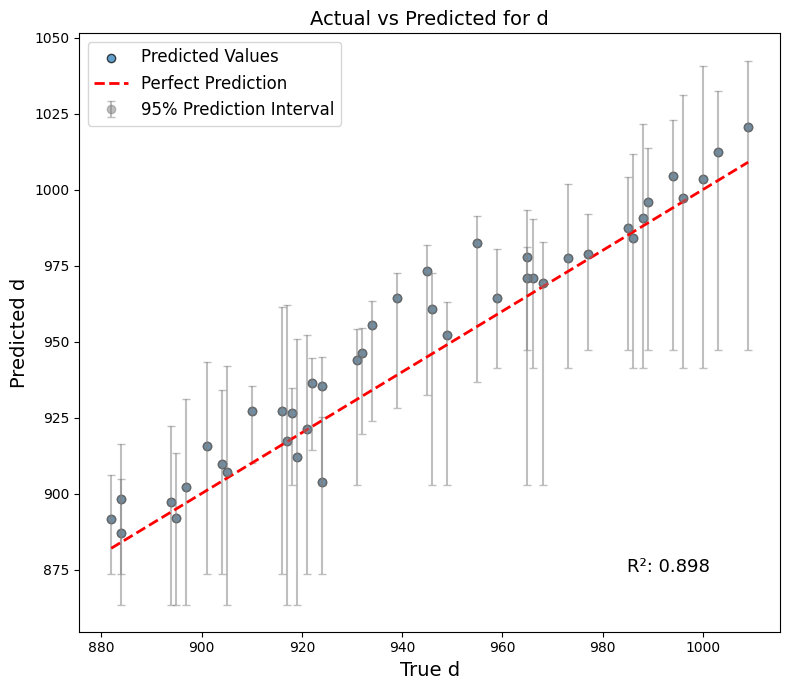

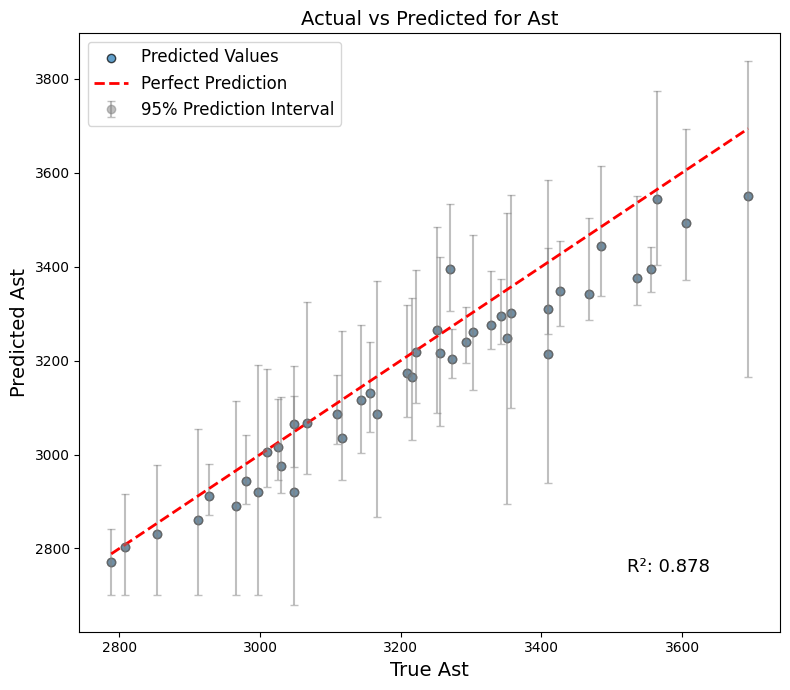

In [ ]:
parity_with_confidence(models, X_test_new, y_test_new)

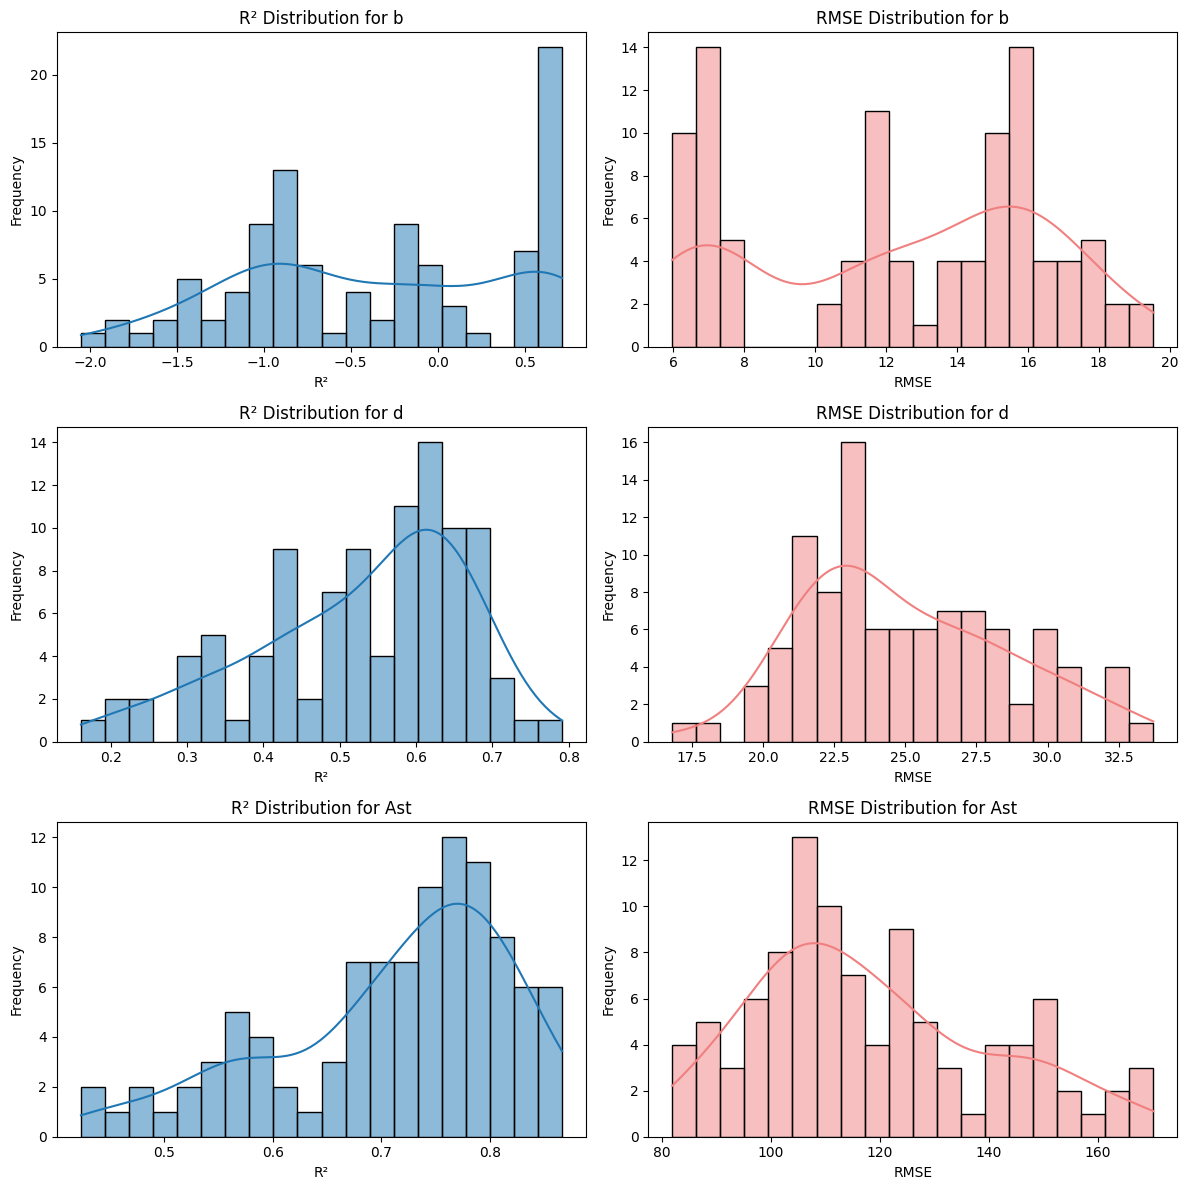

In [ ]:
plot_r2_rmse(models, X_test_new, y_test_new)

#Random forest


In [ ]:
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', MultiOutputRegressor(
        TransformedTargetRegressor(
            regressor=RandomForestRegressor(n_estimators=100, random_state=42),
            transformer=StandardScaler()
        )
    ))
])

models = train_models(rf_pipeline, X_train, y_train, n_iterations=100)

In [ ]:
joblib.dump(models, 'bootstrapped_rf_models.pkl')

['bootstrapped_rf_models.pkl']

In [ ]:
models = joblib.load('bootstrapped_rf_models.pkl')

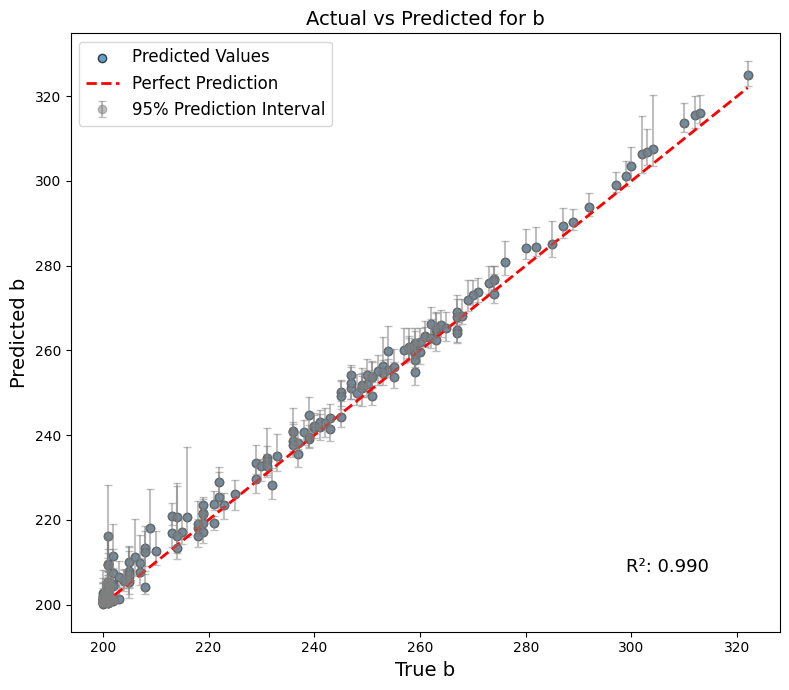

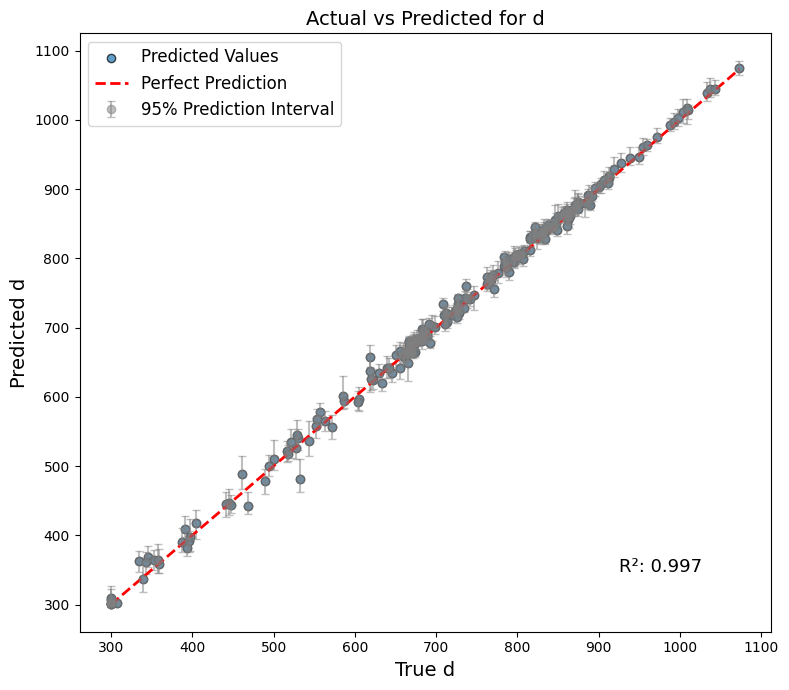

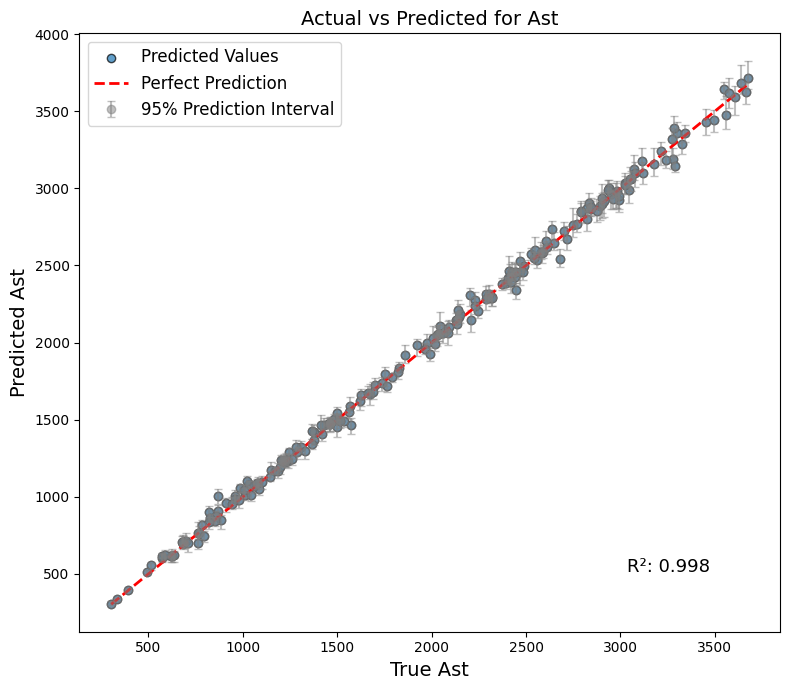

In [ ]:
parity_with_confidence(models, X_test, y_test)

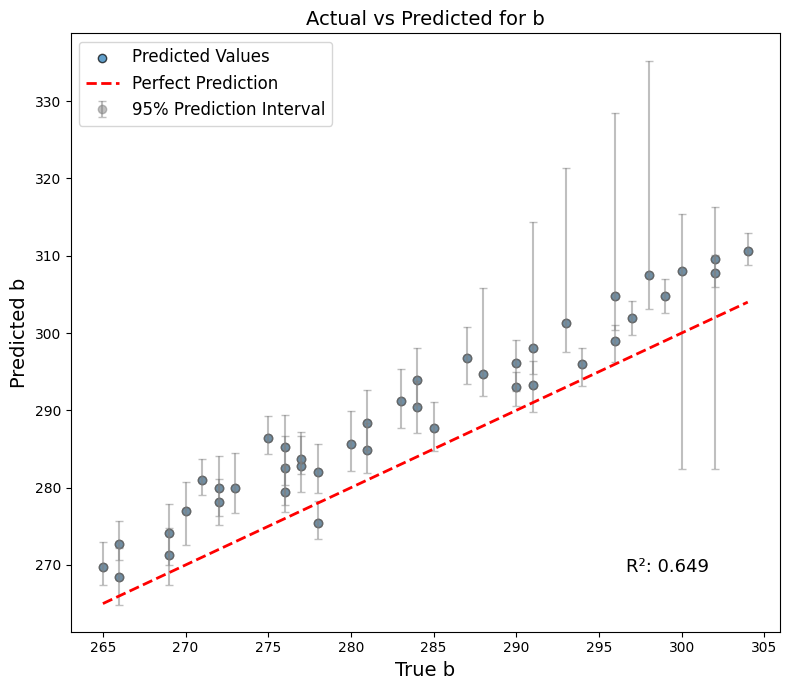

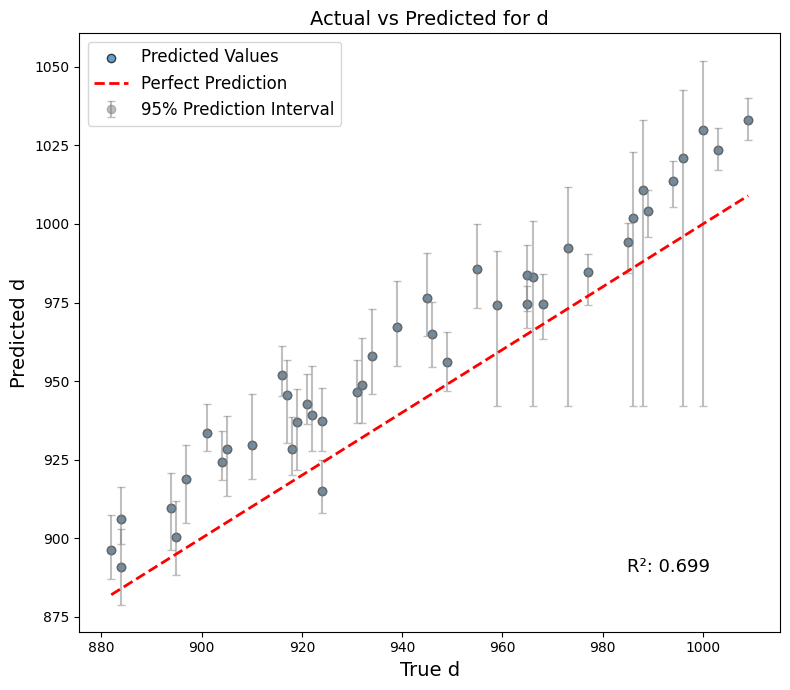

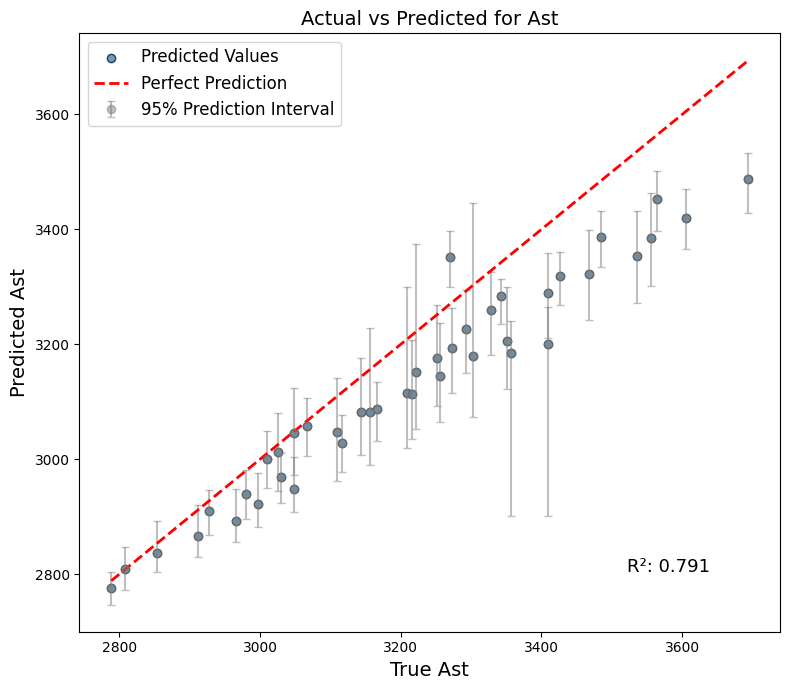

In [ ]:
parity_with_confidence(models, X_test_new, y_test_new)

#MLP 1

In [ ]:
# ===============================
# Define the MLP pipeline
# ===============================

mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),       # Scale input features
    ('regressor', MultiOutputRegressor( # Handle multiple outputs (b, d, Ast)
        TransformedTargetRegressor(     # Scale each output internally
            regressor=MLPRegressor(
                hidden_layer_sizes=(16, 16),
                activation='relu',
                solver='adam',
                learning_rate_init=0.001,
                max_iter=1000,
                alpha=1e-4,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=20,
                random_state=42
            ),
            transformer=StandardScaler()
        )
    ))
])

# ===============================
# Bootstrapping training
# ===============================

models = train_models(mlp_pipeline, X_train, y_train, n_iterations=100)


In [ ]:
joblib.dump(models, 'bootstrapped_mlp1_models.pkl')

['bootstrapped_mlp1_models.pkl']

In [ ]:
models = joblib.load('bootstrapped_mlp1_models.pkl')

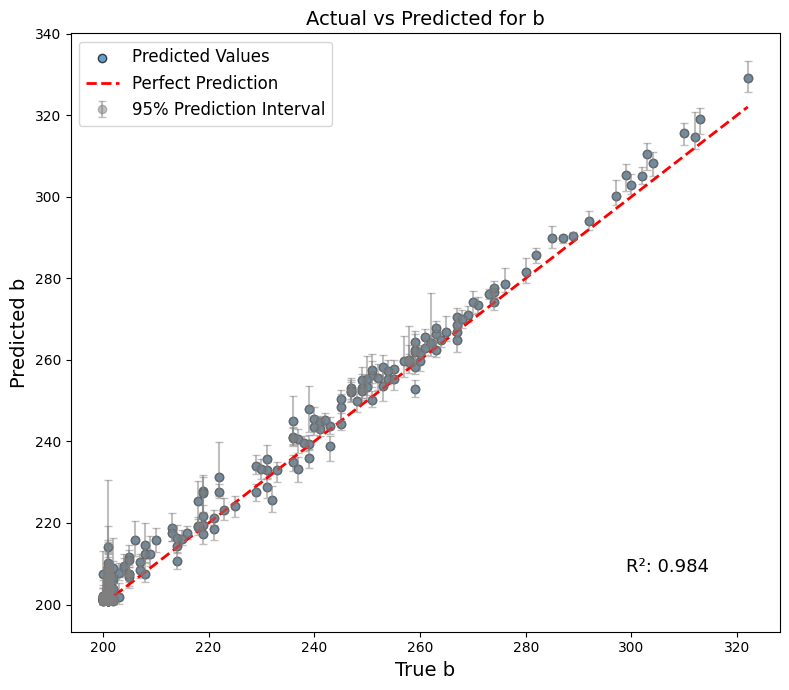

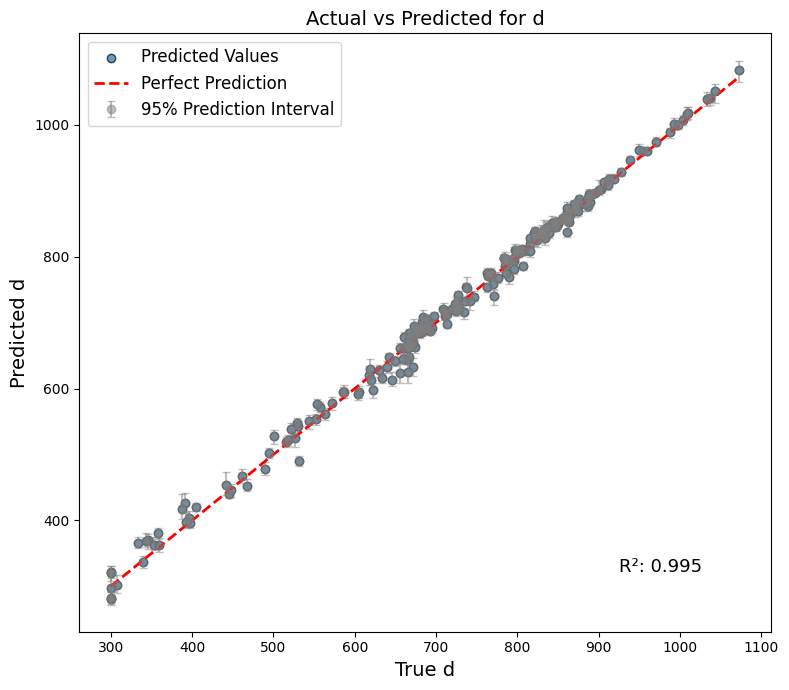

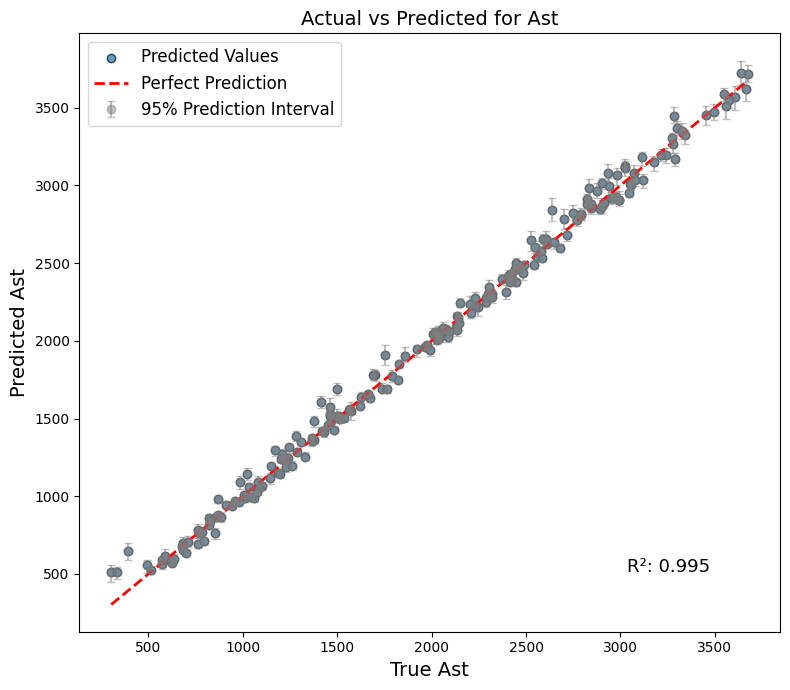

In [ ]:
parity_with_confidence(models, X_test, y_test)

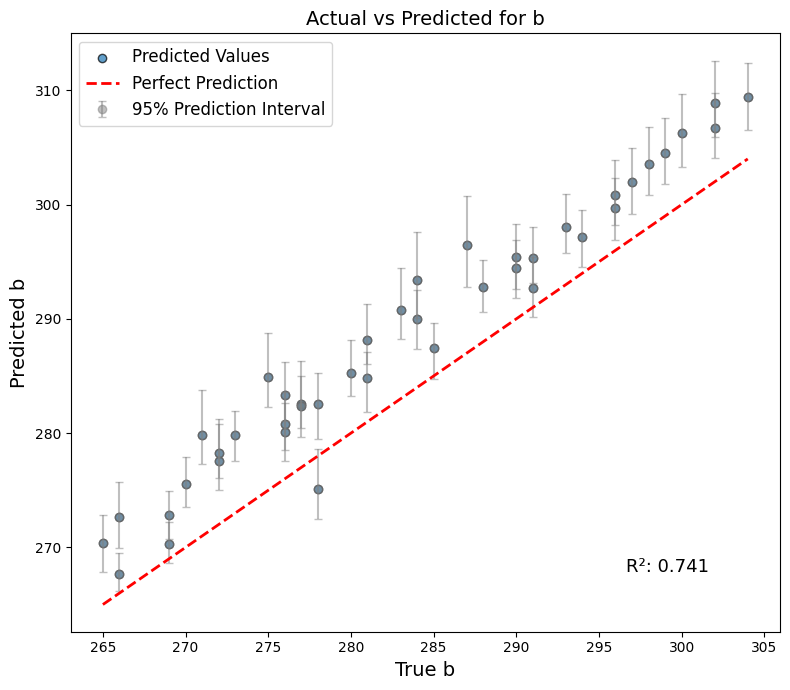

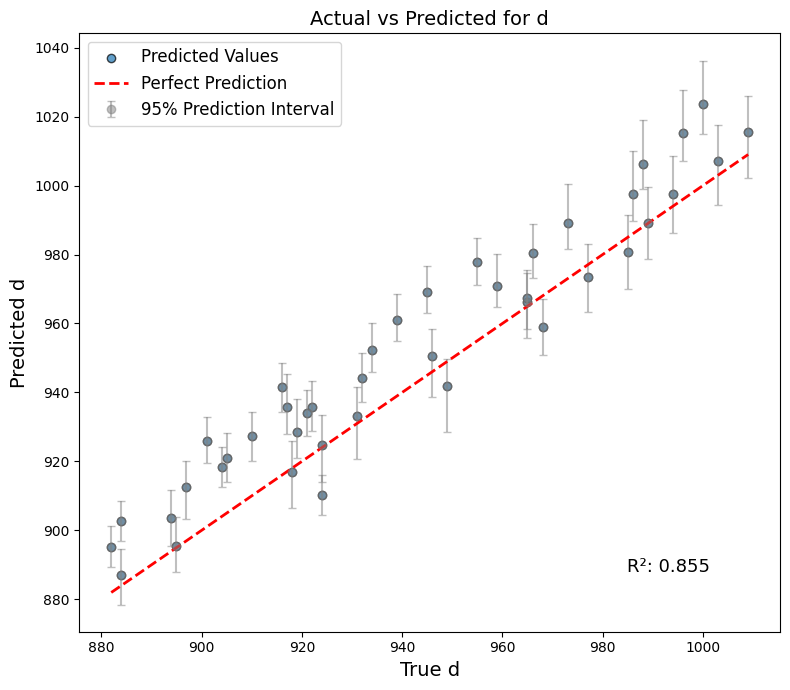

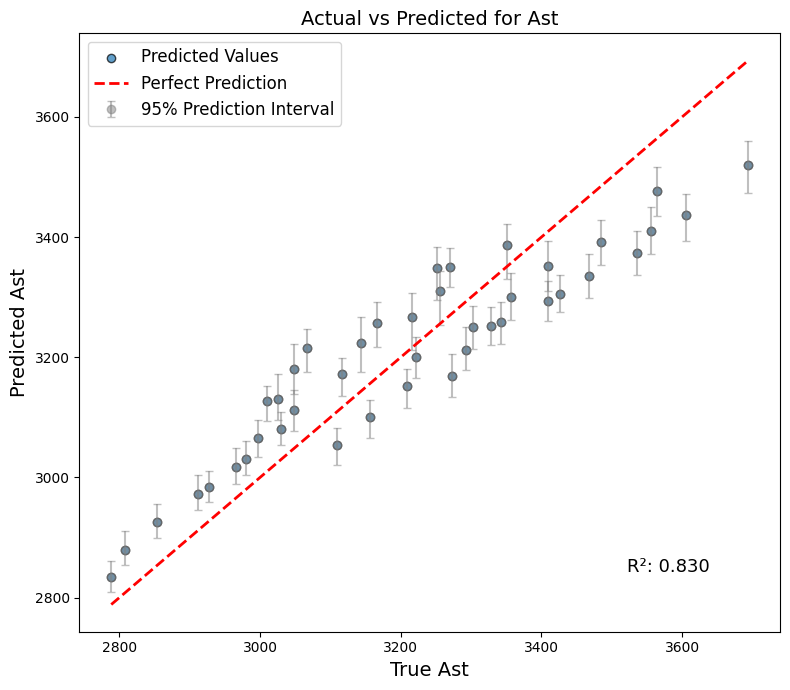

In [ ]:
parity_with_confidence(models, X_test_new, y_test_new)

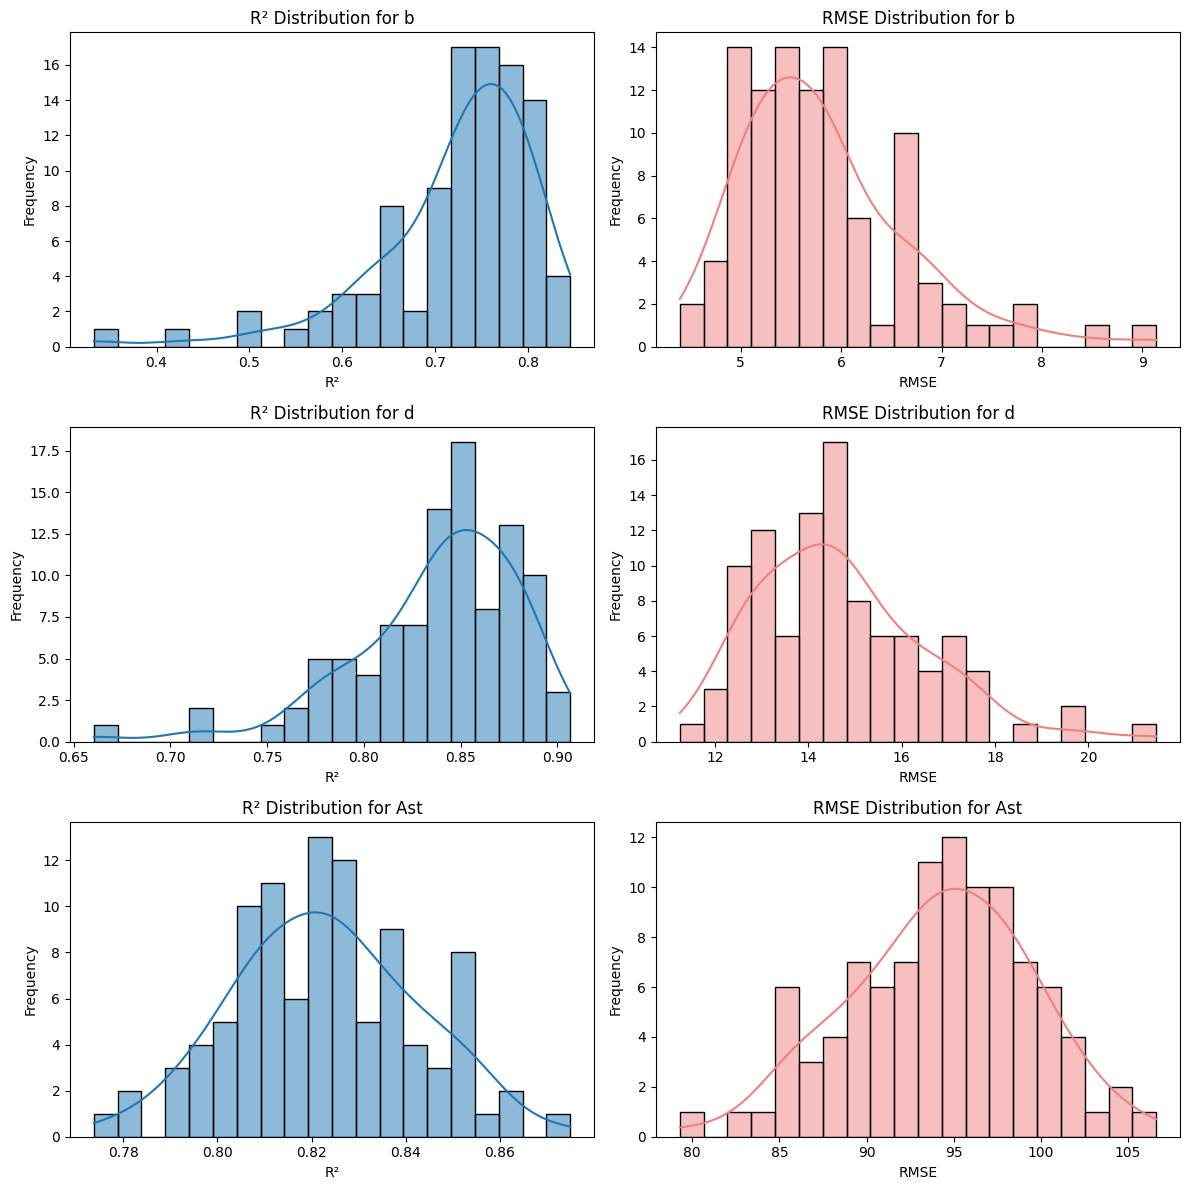

In [ ]:
plot_r2_rmse(models, X_test_new, y_test_new)

#MLP 2 (PyTorch)

In [9]:
# Fix random seeds
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# MLP Model
class MultiOutputNN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, output_dim)
        )

    def forward(self, x):
        return self.net(x)

# Sklearn-style Wrapper
class TorchRegressor:
    def __init__(self, input_dim, output_dim, lr=0.001, weight_decay=1e-4, epochs=500, batch_size=32, device=None):
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.lr = lr
        self.weight_decay = weight_decay
        self.epochs = epochs
        self.batch_size = batch_size
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")

        self.model = MultiOutputNN(input_dim, output_dim).to(self.device)
        self.criterion = nn.MSELoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr, weight_decay=weight_decay)

        # scalers
        self.scaler_X = StandardScaler()
        self.scaler_y = StandardScaler()

        # history
        self.train_losses = []
        self.val_losses = []

    def fit(self, X, y, X_val=None, y_val=None):
        # scale
        X_scaled = self.scaler_X.fit_transform(X)
        y_scaled = self.scaler_y.fit_transform(y)

        # convert to tensors
        X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
        y_tensor = torch.tensor(y_scaled, dtype=torch.float32)
        dataset = TensorDataset(X_tensor, y_tensor)
        loader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        if X_val is not None and y_val is not None:
            X_val_scaled = self.scaler_X.transform(X_val)
            y_val_scaled = self.scaler_y.transform(y_val)
            X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32).to(self.device)
            y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32).to(self.device)

        for epoch in range(self.epochs):
            self.model.train()
            running_loss = 0.0
            for X_batch, y_batch in loader:
                X_batch, y_batch = X_batch.to(self.device), y_batch.to(self.device)
                self.optimizer.zero_grad()
                outputs = self.model(X_batch)
                loss = self.criterion(outputs, y_batch)
                loss.backward()
                self.optimizer.step()
                running_loss += loss.item() * X_batch.size(0)

            epoch_loss = running_loss / len(loader.dataset)
            self.train_losses.append(epoch_loss)

            if X_val is not None and y_val is not None:
                self.model.eval()
                with torch.no_grad():
                    val_outputs = self.model(X_val_tensor)
                    val_loss = self.criterion(val_outputs, y_val_tensor).item()
                self.val_losses.append(val_loss)

                if (epoch + 1) % 50 == 0:
                    print(f"Epoch {epoch+1}/{self.epochs}, Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}")

    def predict(self, X):
        self.model.eval()
        X_scaled = self.scaler_X.transform(X)
        X_tensor = torch.tensor(X_scaled, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            y_pred_scaled = self.model(X_tensor).cpu().numpy()
        return self.scaler_y.inverse_transform(y_pred_scaled)

In [ ]:
reg = TorchRegressor(input_dim=3, output_dim=3, epochs=500)

In [ ]:
models = train_models(reg, X_train, y_train, n_iterations=100)

In [ ]:
joblib.dump(models, 'bootstrapped_mlp2_models.pkl')

['bootstrapped_mlp2_models.pkl']

In [10]:
models = joblib.load('bootstrapped_mlp2_models.pkl')

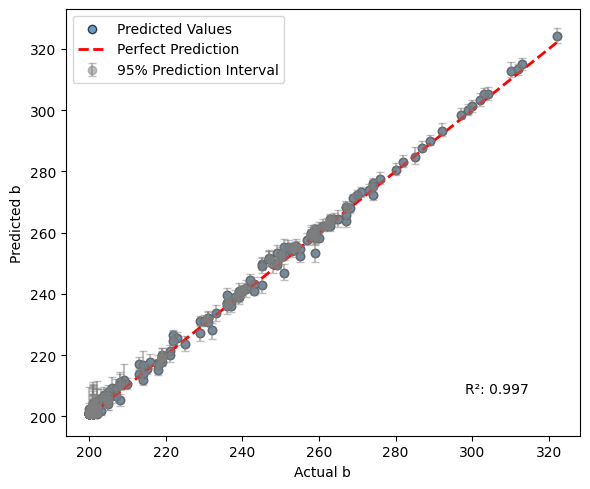

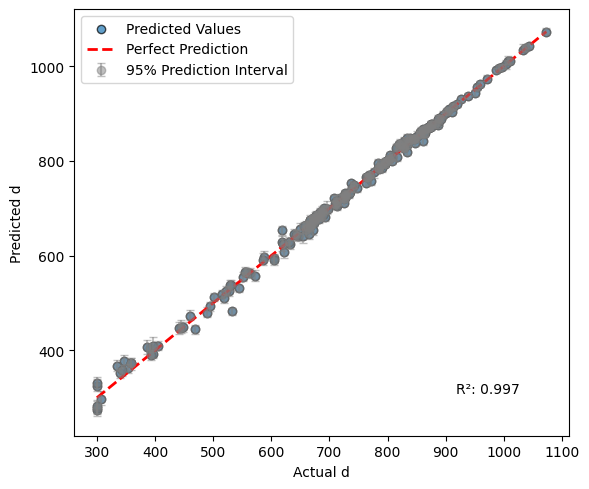

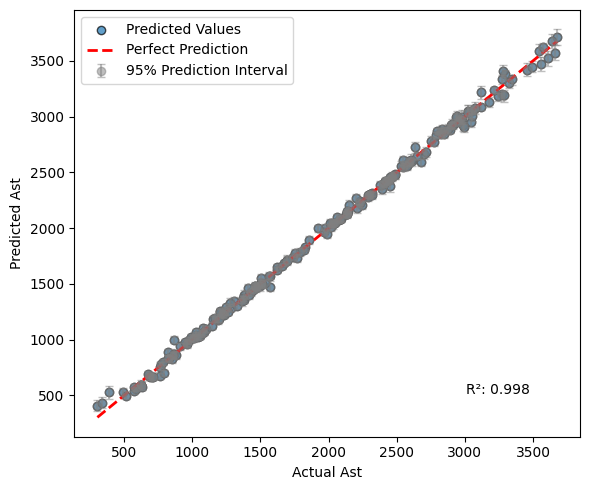

In [15]:
parity_with_confidence(models, X_test, y_test)

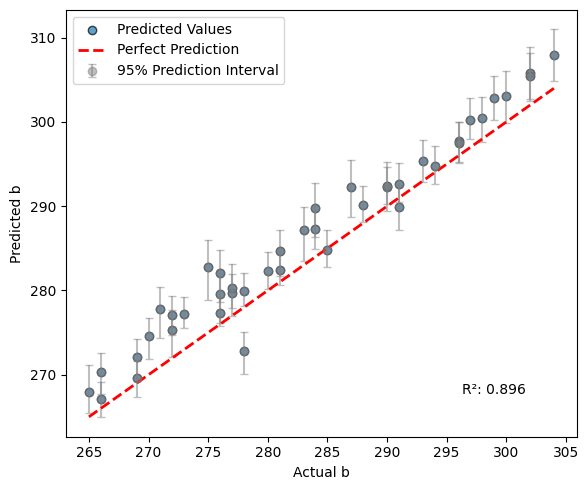

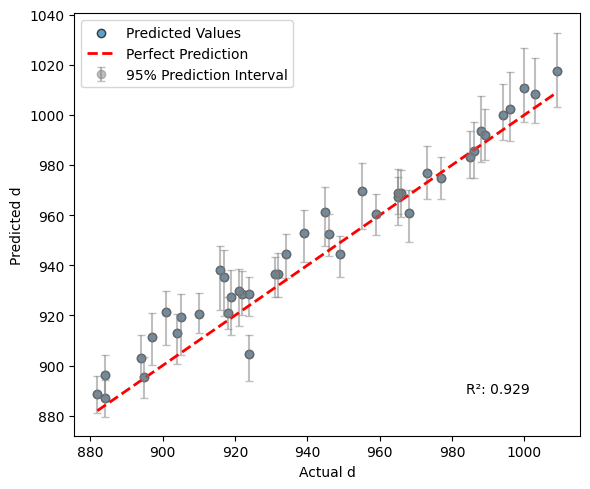

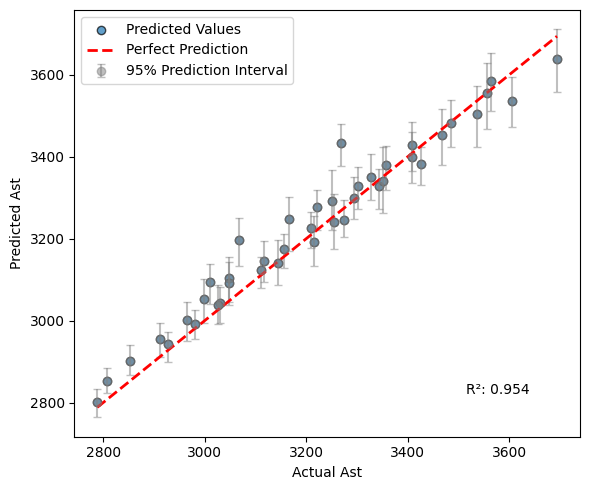

In [16]:
parity_with_confidence(models, X_test_new, y_test_new)